# IEEE 13-bus sequential TD3 training and hourly reference comparison

## Purpose

This notebook trains, evaluates, or views sequential TD3 runs against neutral taps and native RegControl. Each evaluation follows complete days with persistent tap positions. TD3 proposes continuous actions through a discrete tap-execution interface. Results describe this saved validation split and synthetic process; they do not establish convergence, significance, or general performance.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.recipes import prepare_recipe_comparison
from common.reports import show_algorithm_comparison, show_conclusions, show_controller_comparison, show_day, show_paired_counts, show_recipe_comparison, show_training_summary
from common.workflow import run_experiment

print("Repository root resolved.")


Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells. `MODE` selects `train`, `evaluate`, or read-only `view`; `OVERWRITE` affects only writing modes. Keep `MODE = "view"` after the campaign.


In [2]:
FEEDER = "ieee13"  # Named feeder.
DATASET = "ieee13-random"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # train, evaluate, or read saved results.
OVERWRITE = False  # Applies only to train and evaluate.
SHOW_HOURLY_DETAILS = False  # Display the selected day's detailed rows.
TRAINING_DAYS = 1000  # Training only: complete days per run.
REWARD = "band"  # Training only: reward name.
BETA = 1e-5  # Benchmark switching-cost weight per tap step.
REWARD_PARAMETERS = {"beta": BETA}  # Training only: overrides of the reward defaults.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Complete split or a positive day limit.
RUN_NAME = "band_b1e-05"  # Run directory name before _seed<seed>.
PLOT_DAY = 0  # Selected evaluated day by zero-based position.


**Units and interfaces.** Solver voltages, actor proposals, smoothing noise, and exploration noise use physical p.u. values outside the actor tanh. Tap positions are integer grid indices. Replay stores executed ratios. Combined cost adds voltage excursion outside [0.95, 1.05] p.u. and `BETA` times executed tap steps. The recorded reward and benchmark remain distinct saved settings.


In [3]:
results = run_experiment({
    "protocol": "sequential",
    "algorithm": "td3",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "training_days": TRAINING_DAYS,
    "reward": REWARD,
    "reward_parameters": REWARD_PARAMETERS,
    "beta": BETA,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "run_name": RUN_NAME,
    "plot_day": PLOT_DAY,
    "show_hourly_details": SHOW_HOURLY_DETAILS,
    "root": ROOT,
})


Dataset: ieee13-random (data/scenarios/ieee13-random)
Split: validation
Evaluated: 200 days, 4800 hours
Seeds: [0, 1, 2]
Training days per seed: recorded in saved training records
Switching-cost weight beta: 1e-05
Reward: band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}
Display names and run directories:
  TD3 seed 0: results/ieee13-random/seq_td3/band_b1e-05_seed0/
  TD3 seed 1: results/ieee13-random/seq_td3/band_b1e-05_seed1/
  TD3 seed 2: results/ieee13-random/seq_td3/band_b1e-05_seed2/
  Neutral: results/ieee13-random/seq_reference/neutral_b1e-05/
  RegControl: results/ieee13-random/seq_reference/regcontrol_b1e-05/
Mode: view
Overwrite: False
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Day and hour alignment passed for 200 days, 4800 hours, and 5 methods.


## Training records

An episode is one complete 24-decision day. “Training combined cost per day” shows the smoothed seed mean of the fixed evaluation cost on training episodes.

Training includes exploration; these curves are not held-out performance or proof of convergence.

Update counts distinguish critic iterations, delayed actor updates, and target updates.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
TD3 seed 0,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",1000,"{'days': 1000, 'interactions': 24000, 'critic_iterations': 23520, 'actor_updates': 11760, 'target_updates': 11760}"
TD3 seed 1,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",1000,"{'days': 1000, 'interactions': 24000, 'critic_iterations': 23520, 'actor_updates': 11760, 'target_updates': 11760}"
TD3 seed 2,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",1000,"{'days': 1000, 'interactions': 24000, 'critic_iterations': 23520, 'actor_updates': 11760, 'target_updates': 11760}"


band_b1e-05_seed0: 1000 completed episodes, 24000 environment interactions
band_b1e-05_seed1: 1000 completed episodes, 24000 environment interactions
band_b1e-05_seed2: 1000 completed episodes, 24000 environment interactions


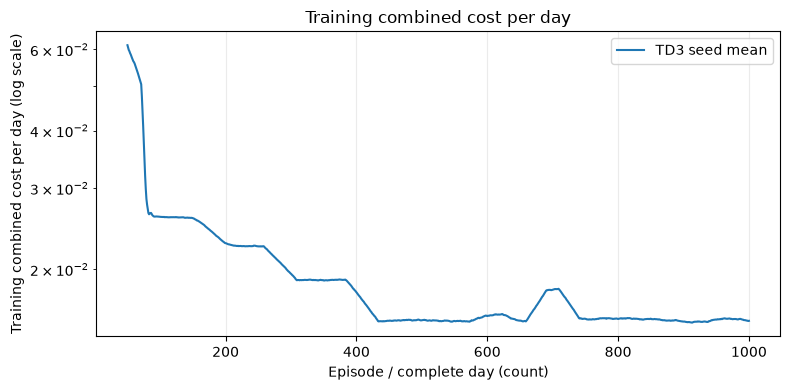

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
show_training_summary(results);


## Overall comparison

Daily voltage cost sums 24 hourly costs. Tap steps include the first movement from neutral. Feasible hours require convergence and every monitored voltage inside the band. Across-seed spread describes three runs, not statistical significance or convergence.


In [5]:
show_controller_comparison(results);


Neutral holds every regulator ratio at 1.0. RegControl uses the feeder's native regulator control.

Hourly voltage cost is the mean squared excursion outside [0.95, 1.05] p.u. over 41 monitored line-ground voltage measurements; in-band measurements contribute zero. Daily voltage cost sums 24 hourly costs, and the table averages these daily totals across evaluation days. Lower cost is better. Beta weights tap movement; it is not a monetary price.

Method,Mean daily combined cost,Mean daily voltage cost,Mean daily switching cost,Mean absolute deviation (p.u.),Mean tap steps/day,Feasible hours (%),Days
TD3 seed 0,1.73207e-02,1.68407e-02,4.80000e-04,5.0607e-02,48.000,0.0,200
TD3 seed 1,1.70416e-02,1.64574e-02,5.84200e-04,5.0253e-02,58.420,0.0,200
TD3 seed 2,1.73207e-02,1.68407e-02,4.80000e-04,5.0607e-02,48.000,0.0,200
Neutral,1.61102e-02,1.61102e-02,0.00000e+00,4.1134e-02,0.000,14.0,200
RegControl,2.12384e-03,5.27494e-04,1.59635e-03,2.3057e-02,159.635,32.4,200


TD3 statistic,Mean daily combined cost,Mean daily voltage cost,Mean daily switching cost,Mean absolute deviation (p.u.),Mean tap steps/day,Feasible hours (%)
Across-seed mean,1.72277e-02,1.67130e-02,5.14733e-04,5.0489e-02,51.473,0.0
Sample standard deviation,1.61153e-04,2.21313e-04,6.01599e-05,2.0434e-04,6.016,0.0


### Paired daily counts

Counts compare exact saved combined costs on matched days. Equality is exact, not a practical-equivalence test, and counts do not show improvement size.


In [6]:
show_paired_counts(results)


TD3 run,Reference,Lower-cost days,Equal-cost days,Higher-cost days
TD3 seed 0,Neutral,72,0,128
TD3 seed 0,RegControl,0,0,200
TD3 seed 1,Neutral,77,0,123
TD3 seed 1,RegControl,0,0,200
TD3 seed 2,Neutral,72,0,128
TD3 seed 2,RegControl,0,0,200


## Selected-day behavior

The selected day is illustrative because hourly loads are independently generated, not a measured daily shape. Changing `PLOT_DAY` or the detail switch changes presentation only.


Selected day: validation-0000


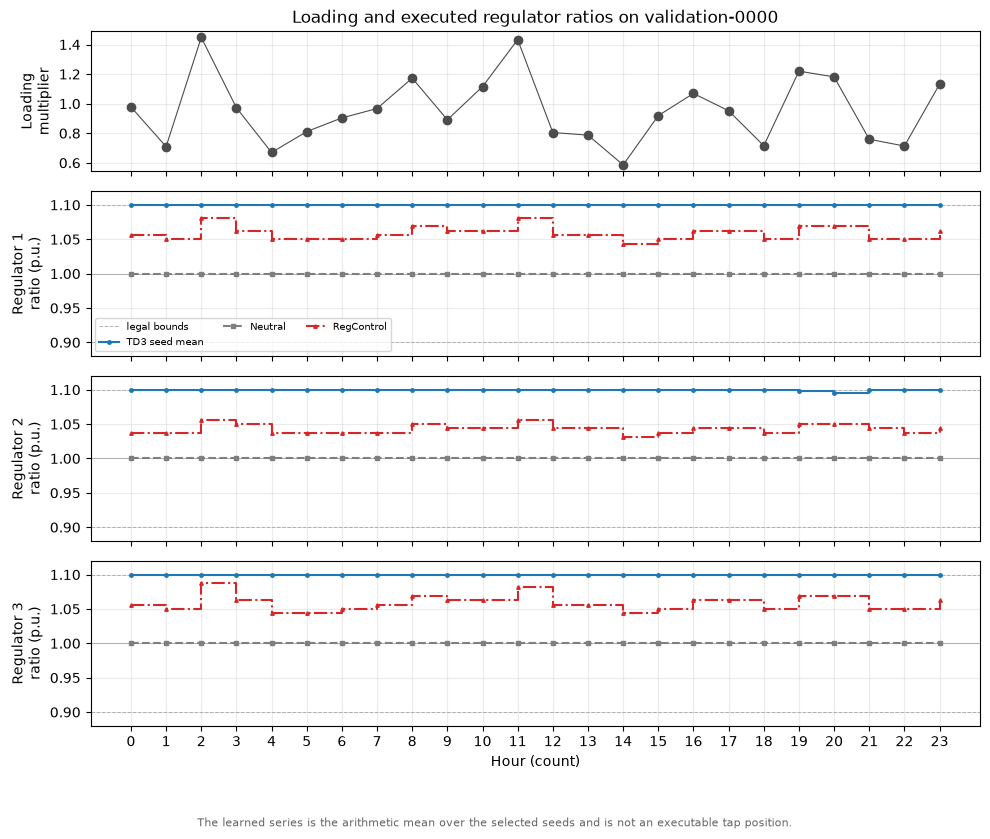

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

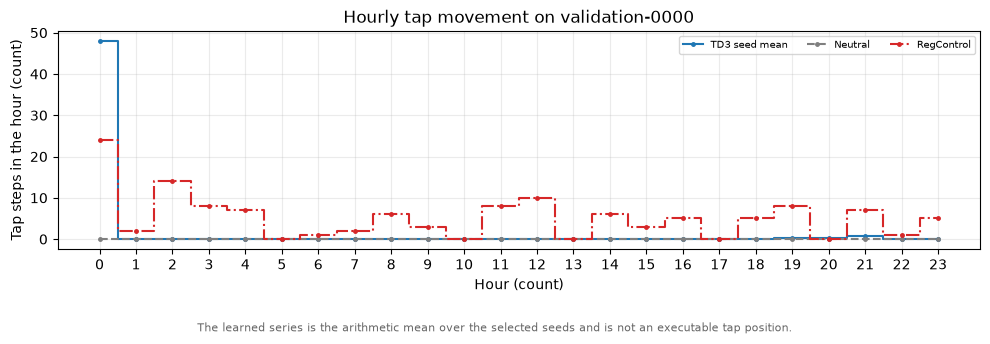

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

Switching cost is tap steps times beta (1e-05).

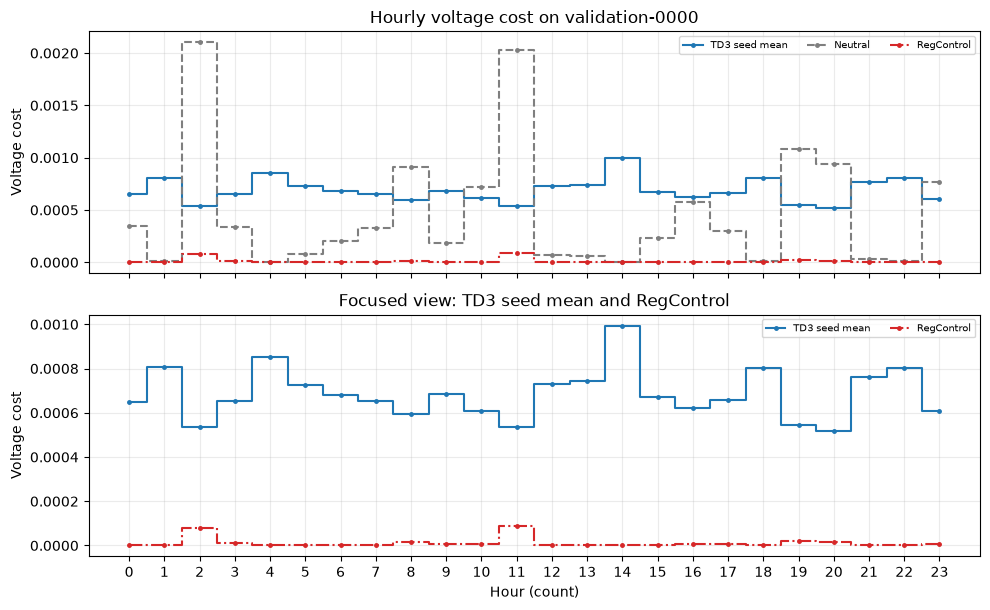

The upper panel keeps every method. The lower panel repeats the controller series without Neutral so their smaller differences remain readable.

Hourly detail table hidden. Set SHOW_HOURLY_DETAILS = True to display it.


In [7]:
show_day(results, PLOT_DAY, SHOW_HOURLY_DETAILS);


## Comparison with sequential DDPG

This compares two documented learner recipes, not an isolated test of twin critics. Exogenous loads and neutral initial taps match, while later observation trajectories can differ after executed actions.


In [8]:
ddpg_results = run_experiment({
    "protocol": "sequential",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": "view",
    "overwrite": False,
    "training_days": TRAINING_DAYS,
    "reward": REWARD,
    "reward_parameters": REWARD_PARAMETERS,
    "beta": BETA,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "run_name": RUN_NAME,
    "plot_day": PLOT_DAY,
    "show_hourly_details": SHOW_HOURLY_DETAILS,
    "root": ROOT,
})


Dataset: ieee13-random (data/scenarios/ieee13-random)
Split: validation
Evaluated: 200 days, 4800 hours
Seeds: [0, 1, 2]
Training days per seed: recorded in saved training records
Switching-cost weight beta: 1e-05
Reward: band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}
Display names and run directories:
  DDPG seed 0: results/ieee13-random/seq_ddpg/band_b1e-05_seed0/
  DDPG seed 1: results/ieee13-random/seq_ddpg/band_b1e-05_seed1/
  DDPG seed 2: results/ieee13-random/seq_ddpg/band_b1e-05_seed2/
  Neutral: results/ieee13-random/seq_reference/neutral_b1e-05/
  RegControl: results/ieee13-random/seq_reference/regcontrol_b1e-05/
Mode: view
Overwrite: False
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Day and hour alignment passed for 200 days, 4800 hours, and 5 methods.


In [9]:
show_algorithm_comparison(results, ddpg_results)


Algorithm,Seed,Mean daily voltage cost,Mean tap steps/day,Mean daily switching cost,Mean daily combined cost,Feasible hours
TD3,0,1.68407e-02,48,4.80000e-04,1.73207e-02,0 / 4800
TD3,1,1.64574e-02,58.42,5.84200e-04,1.70416e-02,0 / 4800
TD3,2,1.68407e-02,48,4.80000e-04,1.73207e-02,0 / 4800
DDPG,0,4.23560e-04,72.68,7.26800e-04,1.15036e-03,740 / 4800
DDPG,1,4.87733e-04,59.85,5.98500e-04,1.08623e-03,390 / 4800
DDPG,2,4.15430e-04,88.605,8.86050e-04,1.30148e-03,1841 / 4800


Algorithm,Mean daily voltage cost,Mean tap steps/day,Mean daily switching cost,Mean daily combined cost,Feasible hours
TD3,1.67130e-02 ± 2.21313e-04,51.4733 ± 6.01599,5.14733e-04 ± 6.01599e-05,1.72277e-02 ± 1.61153e-04,0 ± 0 / 4800
DDPG,4.42241e-04 ± 3.96062e-05,73.7117 ± 14.4052,7.37117e-04 ± 1.44052e-04,1.17936e-03 ± 1.10515e-04,990.333 ± 757.199 / 4800


Seed,TD3 lower,Equal,TD3 higher,Mean TD3 − DDPG
0,0,0,200,1.61704e-02
1,0,0,200,1.59554e-02
2,0,0,200,1.60193e-02


Pairs share exogenous loads and neutral initial taps. Their observation trajectories can differ after controllers execute different taps.

## Recipe comparison

The TD3 column comes from the selected runs' saved records. The DDPG column comes from the saved description beside the reused runs. Each value is marked `recorded` or `reconstructed`; absent values remain explicit. Three seeds support no significance or convergence claim.


In [10]:
recipes = prepare_recipe_comparison(results, ddpg_results, SEEDS)
show_recipe_comparison(recipes)


Setting,TD3,DDPG
hidden_layers,actor 400/300; two critic branches 400/300 (reconstructed),actor 400/300; critic 400/300 with a merged 300-unit layer (reconstructed)
warmup,20 days; 480 interactions (recorded),20 days; 480 interactions (reconstructed)
learning_start_interaction,481 (recorded),64 (reconstructed)
layer_normalization,none (reconstructed),actor hidden layers and critic state/merged hidden layers (reconstructed)
gradient_clipping,none (reconstructed),actor max norm 1.0; critic max norm 1.0 (reconstructed)
initialization,torch_default_linear (recorded),"fan-in uniform; actor and critic outputs uniform on [-0.003, 0.003] (reconstructed)"
actor_learning_rate,0.0003 (recorded),0.0001 (reconstructed)
critic_learning_rate,0.0003 (recorded),0.001 (reconstructed)
critic_count,2 (reconstructed),1 (reconstructed)
batch_size,256 (recorded),64 (reconstructed)


## Conclusions


In [11]:
show_conclusions(results)


The validation evaluation covers 200 days for 3 TD3 seeds, beta 1e-05, and 1000 complete training days per seed.

Across 3 independent seeds, TD3 mean daily combined cost is 1.72277e-02 with sample standard deviation 1.61153e-04. This is higher than Neutral (1.61102e-02) and higher than RegControl (2.12384e-03).

TD3 averages voltage cost 1.67130e-02, mean absolute deviation 5.0489e-02 p.u., 51.473 tap steps/day, and 0.0% feasible hours. Neutral uses 0.000 steps/day with voltage cost 1.61102e-02, mean absolute deviation 4.1134e-02 p.u., and 14.0% feasible hours; RegControl uses 159.635 steps/day with voltage cost 5.27494e-04, mean absolute deviation 2.3057e-02 p.u., and 32.4% feasible hours.

Against RegControl, TD3's voltage cost is higher than RegControl's, its tap steps are lower than RegControl's, and its feasible hours are lower than RegControl's.

The saved TD3 policies are saturated at the tap limits: the boundary share of executed regulator-hour actions is TD3 seed 0 100.0%, TD3 seed 1 97.6%, TD3 seed 2 100.0%.

These results are limited to the validation split, these dataset inputs, and the recorded training budget.